# DL 2026 A1

# Part A – Build the Classifier

## Data Splitting

### Hold-Out Validation

The dataset is split into training/validation/testing splits. Each split is grouped by subjects, so all instances from one subject goes into one split to prevent subject leakage. The data is split using stratification so class proportions stay similar. This Hold-Out Validation is used as computing Cross-Validation folds across this image dataset is computationally expensive.

In [ ]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

root = Path("../data_resized")

rows = []
for p in root.rglob("*"):
    if p.is_file() and ".ipynb_checkpoints" not in p.parts and p.suffix.lower() == ".png":
        rel = p.relative_to(root).parts
        if len(rel) >= 4:
            label, subject, instance = rel[0], rel[1], rel[2]
            rows.append({
                "path": str(p),
                "label": label,
                "subject": subject,
                "instance": instance,
                "instance_id": f"{label}/{subject}/{instance}"
            })

df = pd.DataFrame(rows)

# Split at instance level first (prevents frame leakage)
inst = df[["instance_id", "label", "subject"]].drop_duplicates().reset_index(drop=True)

# 1) train+val vs test (subject-grouped)
sgkf1 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
trainval_idx, test_idx = next(sgkf1.split(inst.index, inst["label"], groups=inst["subject"]))

trainval = inst.iloc[trainval_idx].copy()
test = inst.iloc[test_idx].copy()

# 2) train vs val from trainval
sgkf2 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx2, val_idx2 = next(sgkf2.split(trainval.index, trainval["label"], groups=trainval["subject"]))

train = trainval.iloc[train_idx2].copy()
val = trainval.iloc[val_idx2].copy()

# Map instance splits back to frame-level file lists
train_paths = df[df["instance_id"].isin(train["instance_id"])].drop_duplicates("instance_id")["path"].tolist()
val_paths   = df[df["instance_id"].isin(val["instance_id"])].drop_duplicates("instance_id")["path"].tolist()
test_paths  = df[df["instance_id"].isin(test["instance_id"])].drop_duplicates("instance_id")["path"].tolist()

print(df.head())
print(f"\nTraining split: {len(train_paths)}, Validation split: {len(val_paths)}, Test split: {len(test_paths)}")

                                                path      label subject  \
0  ../data_resized/MoveAhead/S13/Instance9/S13_mo...  MoveAhead     S13   
1  ../data_resized/MoveAhead/S13/Instance9/S13_mo...  MoveAhead     S13   
2  ../data_resized/MoveAhead/S13/Instance9/S13_mo...  MoveAhead     S13   
3  ../data_resized/MoveAhead/S13/Instance9/S13_mo...  MoveAhead     S13   
4  ../data_resized/MoveAhead/S13/Instance9/S13_mo...  MoveAhead     S13   

    instance              instance_id  
0  Instance9  MoveAhead/S13/Instance9  
1  Instance9  MoveAhead/S13/Instance9  
2  Instance9  MoveAhead/S13/Instance9  
3  Instance9  MoveAhead/S13/Instance9  
4  Instance9  MoveAhead/S13/Instance9  

Training split: 690, Validation split: 178, Test split: 191


Approximately a 65/18/17 split.

# Data Exploration

## Class Distribution

Train image-level label counts:
  AllClear: 58
  HaveCommand: 51
  Hover: 60
  Land: 86
  LandingDirection: 32
  MoveAhead: 60
  MoveDownward: 33
  MoveToLeft: 59
  MoveToRight: 59
  MoveUpward: 43
  NotClear: 54
  SlowDown: 56
  WaveOff: 39
Validation image-level label counts:
  AllClear: 11
  HaveCommand: 18
  Hover: 11
  Land: 18
  LandingDirection: 8
  MoveAhead: 19
  MoveDownward: 5
  MoveToLeft: 18
  MoveToRight: 17
  MoveUpward: 10
  NotClear: 18
  SlowDown: 17
  WaveOff: 8


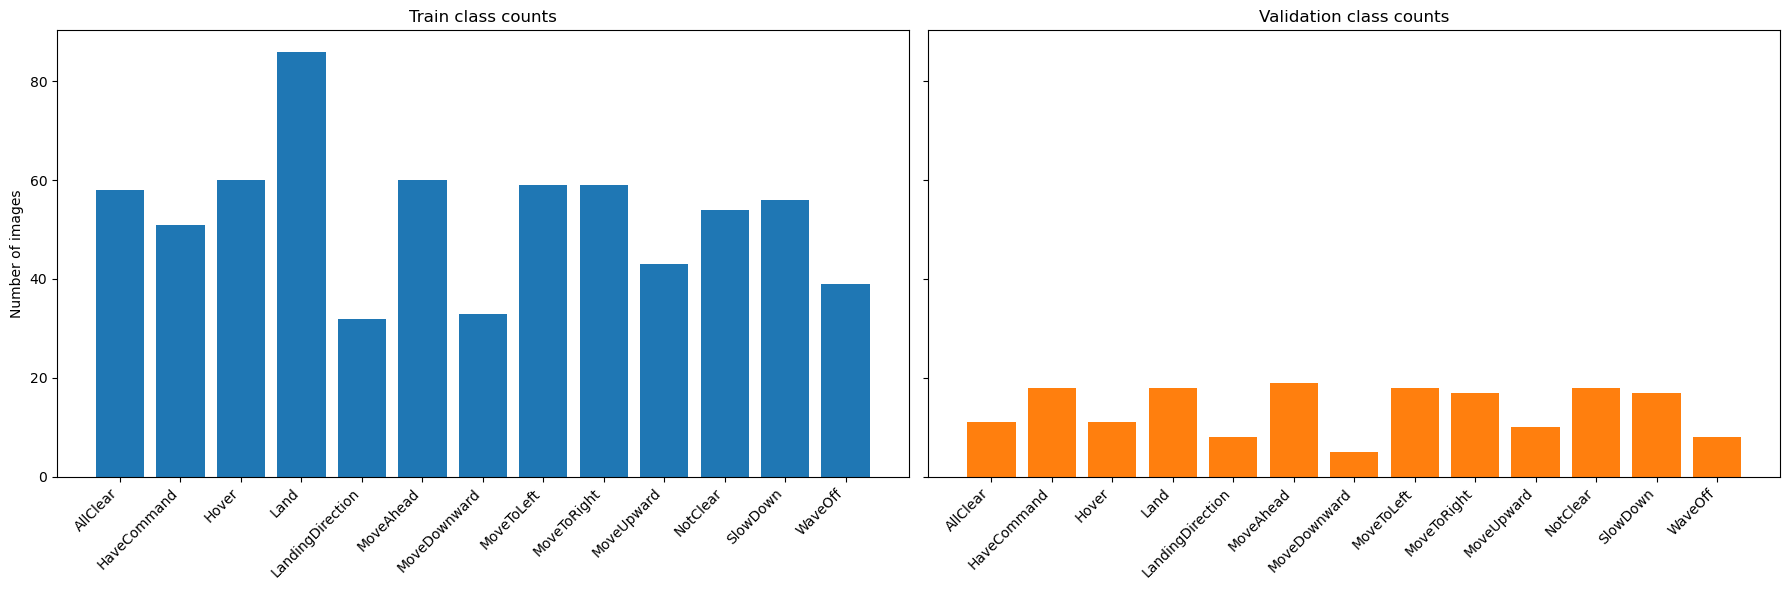

In [ ]:
# Plot train image-level class counts as a column (bar) chart
import matplotlib.pyplot as plt

# Prepare label->index mapping
class_list = sorted(df['label'].unique())
label_to_idx = {l:i for i, l in enumerate(class_list)}

# Train dataframe
train_df = df[df['path'].isin(train_paths)].copy()
train_df['label_idx'] = train_df['label'].map(label_to_idx)

# Counts per class (training split)
image_label_counts = train_df['label'].value_counts().to_dict()
print('Train image-level label counts:')
for k in class_list:
    print(f"  {k}: {image_label_counts.get(k,0)}")

order = class_list
counts = train_df['label'].value_counts().reindex(order).fillna(0).astype(int)

# Validation dataframe
val_df = df[df['path'].isin(val_paths)].copy()
val_df['label_idx'] = val_df['label'].map(label_to_idx)
val_counts = val_df['label'].value_counts().reindex(order).fillna(0).astype(int)

print('Validation image-level label counts:')
for k in order:
    print(f"  {k}: {int(val_counts[k])}")

fig, axes = plt.subplots(1, 2, figsize=(18,6), sharey=True)
axes[0].bar(counts.index, counts.values, color='C0')
axes[0].set_title('Train class counts')
axes[0].set_ylabel('Number of images')
axes[0].tick_params(axis='x', rotation=45)
for tick in axes[0].get_xticklabels():
    tick.set_ha('right')
axes[1].bar(val_counts.index, val_counts.values, color='C1')
axes[1].set_title('Validation class counts')
axes[1].tick_params(axis='x', rotation=45)
for tick in axes[1].get_xticklabels():
    tick.set_ha('right')
plt.tight_layout()
plt.show()

From the above chart, the classes are not entirely balanced, especially `Land` with the highest peak. Address this using a weighted random sampler, in the dataloader to oversample rarer class such as `MoveDownward`.

In [ ]:
# Build a WeightedRandomSampler for training
from torch.utils.data import WeightedRandomSampler

# Weights per sample (file) = inverse frequency of its class
sample_weights = [1.0 / image_label_counts[label] for label in train_df['label'].tolist()]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

## Performance Metric

Because of this class imbalance, accuracy is not the most intuitive metric as the model can get a high score by guessing the majority class. However, it is typically the most human-readable and will be used for the final evaluation. A more appropriate metric is macro-averaged F1 score which averages F1 scores for each class and gives more weight to lower distributed classes which is assessed as part of the classification report interface. For this task a target accuracy of 80% is reasonable, as pre-trained models on gestures data is not as widely available, compared to for example images of cats and dogs. Also because of the 2D-CNN constraint, this task is very complex as give the nature of this data being sequential trying to classify iamges using a 2D-CNN architecture.

An important note is that, since this needs to be implemented in an emergency medical context, typically ~99% accuracy is the standard, however again given the constraints it would be infeasible and model development would keep iterating over and over without stopping.

## Plotting some Images

Image ../data_resized/AllClear/S15/Instance4/S15_allClear_HD_instance4_3.png size: (512, 512)
Image ../data_resized/AllClear/S6/Instance5/S6_allClear_HD_instance5_4.png size: (512, 512)
Image ../data_resized/AllClear/S3/Instance7/S3_allClear_HD_instance7_5.png size: (512, 512)
Image ../data_resized/AllClear/S1/Instance8/S1_allClear_HD_instance8_1.png size: (512, 512)
Image ../data_resized/HaveCommand/S11/Instance3/S11_haveCommand_HD_instance3_5.png size: (512, 512)
Image ../data_resized/HaveCommand/S13/Instance5/S13_haveCommand_HD_instance5_2.png size: (512, 512)
Image ../data_resized/HaveCommand/S12/Instance3/S12_haveCommand_HD_instance3_1.png size: (512, 512)
Image ../data_resized/HaveCommand/S9/Instance7/S9_haveCommand_HD_instance7_2.png size: (512, 512)
Image ../data_resized/Hover/S5/Instance8/S5_hover_HD_instance8_4.png size: (512, 512)
Image ../data_resized/Hover/S1/Instance6/S1_hover_HD_instance6_5.png size: (512, 512)
Image ../data_resized/Hover/S6/Instance1/S6_hover_HD_instanc

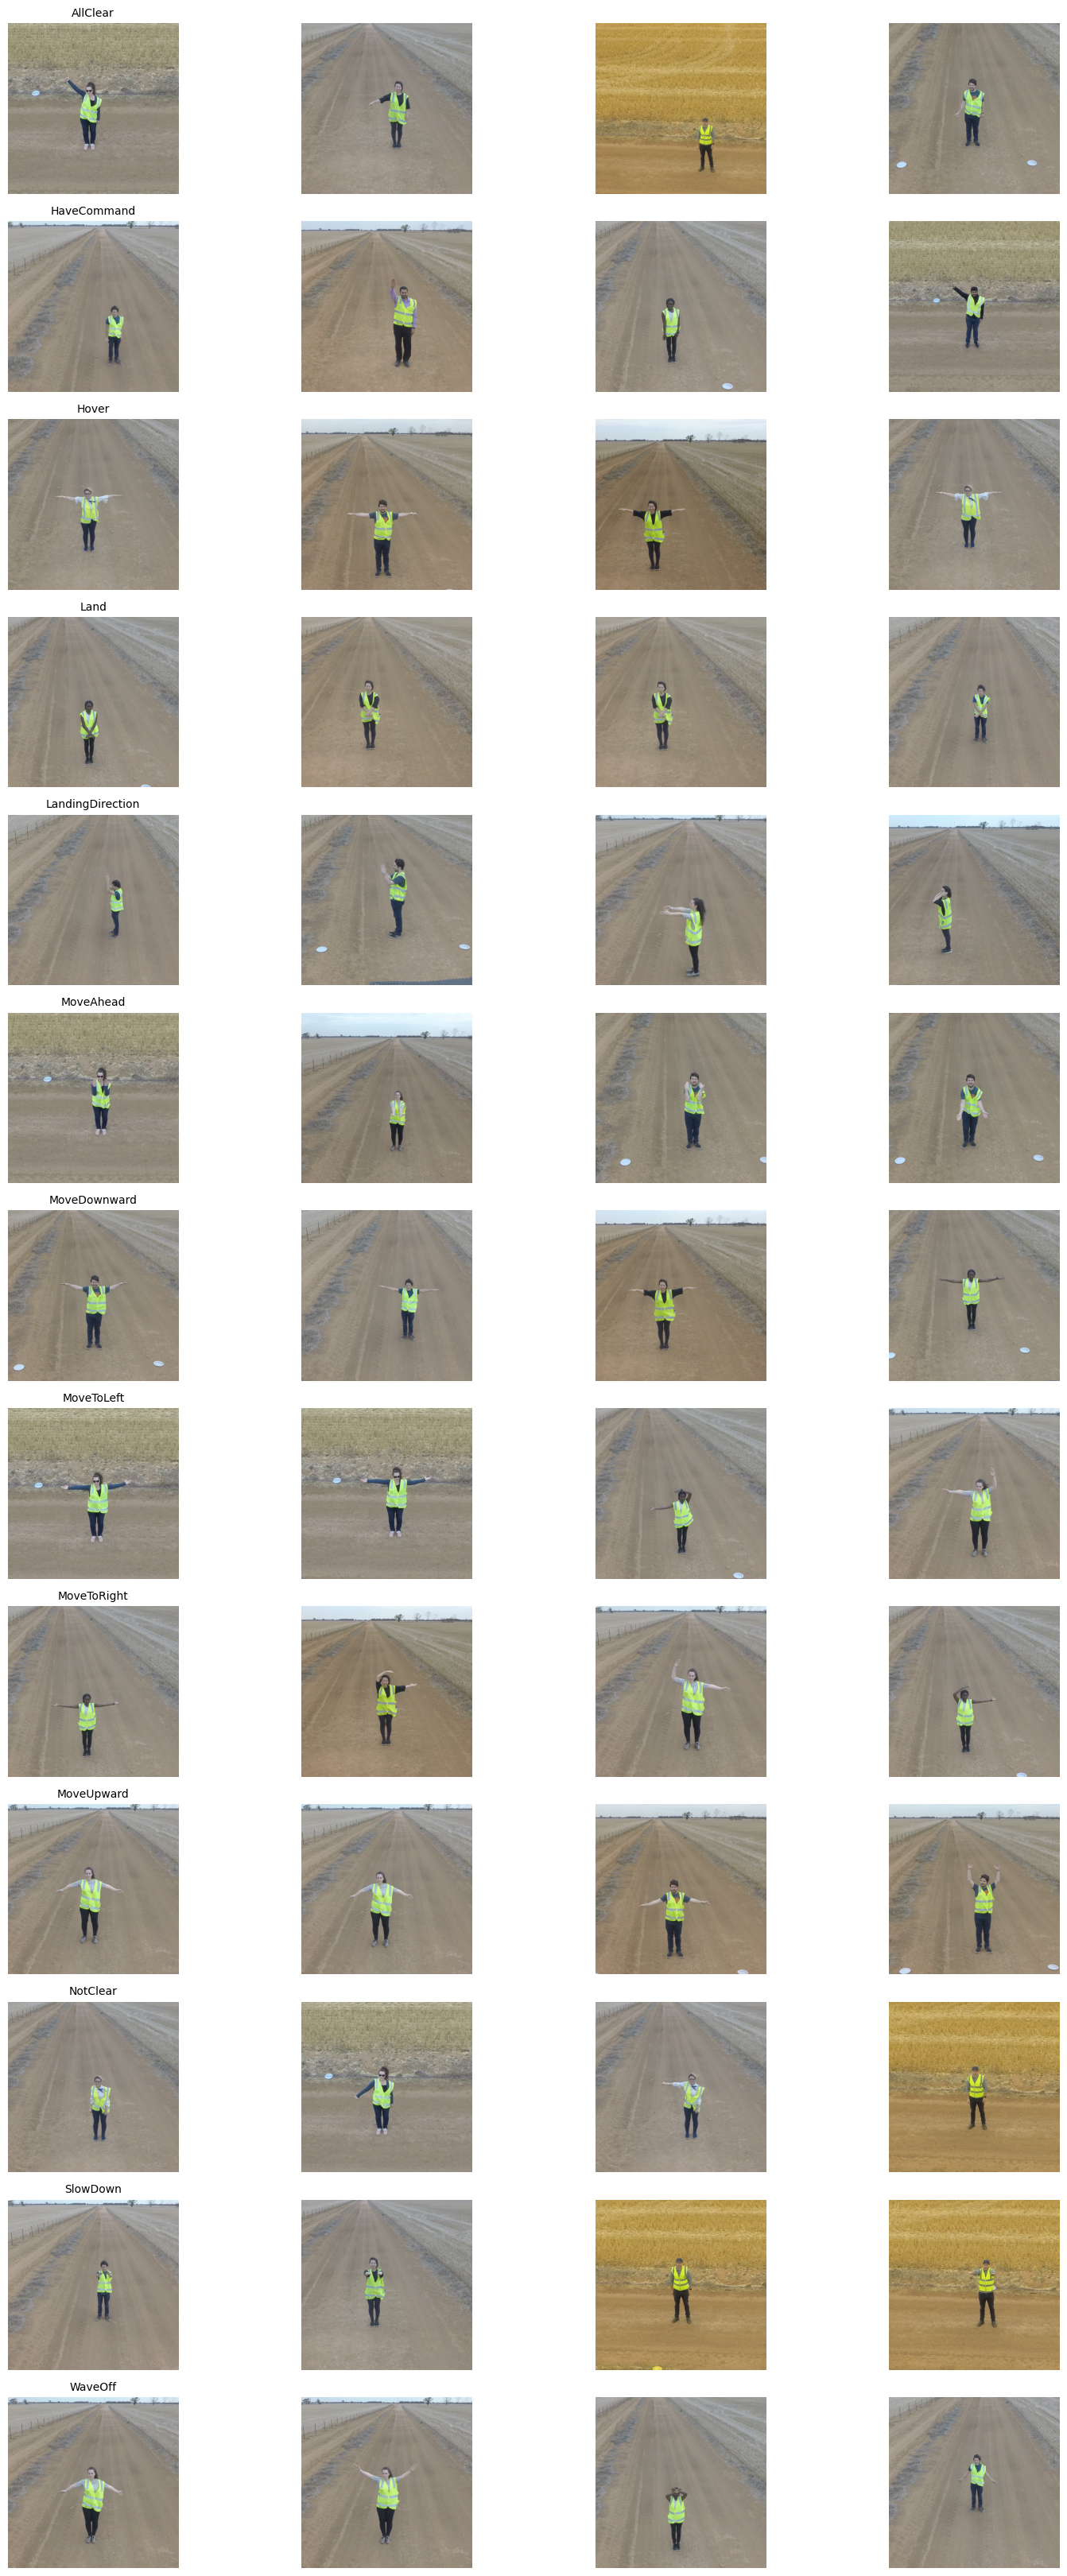

In [ ]:
from pathlib import Path
import random
from PIL import Image
import matplotlib.pyplot as plt

root = Path("../data_resized")

# list classes
classes = sorted([p.name for p in root.iterdir() if p.is_dir() and not p.name.startswith(".")])

# Plot 4 random samples from each class
samples_per_class = 4

fig, axes = plt.subplots(len(classes), samples_per_class, figsize=(16, 2.5 * len(classes)))

for i, cls in enumerate(classes):
    class_dir = root / cls
    files = [p for p in class_dir.rglob("*") if p.is_file() and p.suffix.lower() == ".png"]
    chosen = random.sample(files, min(samples_per_class, len(files)))

    for j, img_path in enumerate(chosen):
        ax = axes[i, j]
        img = Image.open(img_path).convert("RGB")
        print(f"Image {img_path} size: {img.size}")
        ax.imshow(img)
        ax.axis("off")

        if j == 0:
            ax.set_title(cls, fontsize=10)

plt.tight_layout()
plt.show()

These are 512 x 512 pixel RGB images. From these samples, class similarity will be a big challenge, for example the Hover frames are very similar to the MoveToLeft frames (subjects are standing in similar positions). Also the amount of noise is considerable compared to the subject itself. This could make models learn the background/environment of the images and classify based off on similar background rather than the gesture, for example AllClear frame 3 and SlowDown frame 3 have similar coloured backgrounds, which could misclassify the images as one of the classes. Address this using some light colour augementation for training.

## Dataset Preparation

Because this is a sequence image classification problem, the 5 frame images will need to be parsed and mapped to a label at once, rather than a single frame. This means a 4D tensor is required ([5, 3, 512, 512]) excluding batch size for now.

In [ ]:
from pathlib import Path
from PIL import Image
import torch
from torch.utils.data import Dataset
from torchvision import transforms

from pathlib import Path
from PIL import Image
import torch
from torch.utils.data import Dataset
from torchvision import transforms

class RedKiteSequenceDataset(Dataset):
    def __init__(self, instance_paths, root_dir="../data_resized", transform=None, seq_transform=None, classes=None):
        self.root_dir = Path(root_dir)
        # Expecting a list of paths pointing to INSTANCE folders, not individual images
        self.instance_paths = [Path(p) for p in instance_paths]
        self.transform = transform
        self.seq_transform = seq_transform

        # Infer classes based on the label folder name
        if classes is None:
            classes = sorted({
                p.relative_to(self.root_dir).parts[0]
                for p in self.instance_paths
                if len(p.relative_to(self.root_dir).parts) >= 2
            })
        self.classes = classes
        self.class_to_idx = {label: idx for idx, label in enumerate(self.classes)}

    def __len__(self):
        return len(self.instance_paths)

    def __getitem__(self, idx):
        file_path = self.instance_paths[idx]
        # Move up to the actual parent folder (e.g., Instance1)
        instance_path = file_path.parent 
        rel_parts = instance_path.relative_to(self.root_dir).parts

        if len(rel_parts) < 1:
            raise ValueError(f"Path does not contain a valid label: {instance_path}")

        label = rel_parts[0]

        frame_paths = sorted(p for p in instance_path.glob("*.png") if ".ipynb_checkpoints" not in p.parts) 

        if len(frame_paths) != 5:
            raise ValueError(f"Expected 5 frames in {instance_path}, but found {len(frame_paths)}")

        # Load and transform all 5 images
        frames = []
        for path in frame_paths:
            img = Image.open(path).convert("RGB")
            if self.transform is not None:
                img = self.transform(img) # Returns a [3, H, W] tensor
            frames.append(img)

        # Stack the individual images into a single 4D tensor
        sequence_tensor = torch.stack(frames, dim=0) # Returns a [5, 3, H, W] tensor
        if self.seq_transform is not None:
            sequence_tensor = self.seq_transform(sequence_tensor)

        target = torch.tensor(self.class_to_idx[label], dtype=torch.long)
        return sequence_tensor, target

base_transform = transforms.Compose([transforms.ToTensor()])

train_dataset = RedKiteSequenceDataset(train_paths, root_dir="../data_resized", transform=base_transform, classes=class_list)
val_dataset = RedKiteSequenceDataset(val_paths, root_dir="../data_resized", transform=base_transform, classes=class_list)
test_dataset = RedKiteSequenceDataset(test_paths, root_dir="../data_resized", transform=base_transform, classes=class_list)

print(f"Train samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")

sample_image, sample_label = train_dataset[0]
print(f"\nSample image Tensor: {sample_image}")
print(f"Sample label idx: {sample_label.item()} ({train_dataset.classes[sample_label.item()]})")

Train samples: 690
Validation samples: 178
Test samples: 191

Sample image Tensor: tensor([[[[0.8235, 0.8235, 0.8235,  ..., 0.8667, 0.8627, 0.8627],
          [0.8157, 0.8157, 0.8196,  ..., 0.8667, 0.8627, 0.8627],
          [0.8118, 0.8118, 0.8157,  ..., 0.8627, 0.8588, 0.8588],
          ...,
          [0.5490, 0.5529, 0.5490,  ..., 0.5961, 0.5961, 0.5961],
          [0.5529, 0.5412, 0.5412,  ..., 0.5882, 0.5882, 0.6000],
          [0.5451, 0.5412, 0.5569,  ..., 0.5882, 0.5804, 0.5922]],

         [[0.8980, 0.8980, 0.8980,  ..., 0.9333, 0.9294, 0.9294],
          [0.8902, 0.8902, 0.8941,  ..., 0.9333, 0.9294, 0.9294],
          [0.8902, 0.8902, 0.8941,  ..., 0.9294, 0.9255, 0.9255],
          ...,
          [0.5020, 0.5020, 0.5020,  ..., 0.5451, 0.5451, 0.5490],
          [0.5059, 0.4902, 0.4941,  ..., 0.5412, 0.5412, 0.5490],
          [0.4941, 0.4902, 0.5098,  ..., 0.5412, 0.5333, 0.5412]],

         [[0.9451, 0.9451, 0.9451,  ..., 0.9725, 0.9686, 0.9686],
          [0.9373, 0.9373

Use a balanced batch size to balance learning speed and model learning. If trained on all samples at once, the GPU would be overloaded.

In [ ]:
from torch.utils.data import DataLoader

# Use the class-balanced sampler for training so rare classes are sampled more often
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    sampler=sampler,
    shuffle=False, # Sampler already shuffles
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

images, labels = next(iter(train_loader))
print(f"Batch images shape: {images.shape}")
print(f"Batch labels shape: {labels.shape}")

Batch images shape: torch.Size([32, 5, 3, 224, 224])
Batch labels shape: torch.Size([32])


5-D tensor includes batch-size. Problem for 2D Convolutional Neural Network.

## Setup PyTorch Device

In [ ]:
from torch import device

# Use GPU if available, otherwise fallback to CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


## Training Utilities

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    correct, total = 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        outputs = model(x)
        loss = criterion(outputs, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * y.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == y).sum().item()
        total += y.size(0)

    return total_loss / total, correct / total


def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    correct, total = 0, 0

    with torch.inference_mode():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)
            loss = criterion(outputs, y)

            total_loss += loss.item() * y.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == y).sum().item()
            total += y.size(0)

    return total_loss / total, correct / total


def run_experiment(model, optimizer, criterion, train_loader, val_loader,
                   epochs=10, name='Model', scheduler = None, ckpt_path=None):
    """Run a training experiment and return history dict."""
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_acc = 0.0

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        if scheduler is not None:
            scheduler.step()

        # Save checkpoint whenever validation accuracy improves
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            if ckpt_path is not None:
                torch.save(model.state_dict(), ckpt_path)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f'  [{name}] Epoch {epoch+1}/{epochs} — '
              f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | '
              f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')

    return history

In [ ]:
def plot_experiments(results, show_train=True, show_val=True):
    """Plot training and validation loss + accuracy for multiple experiments."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Loss
    ax = axes[0]
    for name, hist in results.items():
        epochs = range(1, len(hist['train_loss']) + 1)
        if show_train:
            ax.plot(epochs, hist['train_loss'], label=f'{name} (Train)', marker='o', markersize=4)
        if show_val:
            ax.plot(epochs, hist['val_loss'], label=f'{name} (Val)', marker='x', markersize=4, linestyle='--')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.set_title('Loss')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.7)

    # Accuracy
    ax = axes[1]
    for name, hist in results.items():
        epochs = range(1, len(hist['train_acc']) + 1)
        if show_train:
            ax.plot(epochs, hist['train_acc'], label=f'{name} (Train)', marker='o', markersize=4)
        if show_val:
            ax.plot(epochs, hist['val_acc'], label=f'{name} (Val)', marker='x', markersize=4, linestyle='--')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.set_title('Accuracy')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

## Data Augmentation

Apply some light augmentation including rotation, colour, brightness and contrast. This means the model never sees exactly the same image twice. This effectively increases the size of the training set and forces the model to learn features that are invariant to these transformations. Can also generalise better to different time of day images as the background can be lighter or darker.

Careful augmentation must be used such that horizontal flips should not be injected. This is because some images have left and right specifc gestures such as MoveToLeft and would be reflected, confusing the model into thinking it, the image belongs to the MoveToRight class.

In [ ]:
import torchvision.transforms as T
import torchvision.transforms.functional as F

class ConsistentSequenceAug:
    def __init__(self, degrees=5, translate=(0.03, 0.03), scale=(0.95, 1.05), jitter=(0.2, 0.2, 0.2)):
        self.affine = T.RandomAffine(degrees=degrees, translate=translate,
                                     scale=scale, fill=0)
        self.jitter = T.ColorJitter(brightness=jitter[0], contrast=jitter[1],
                                    saturation=jitter[2])
        self.normalize = T.Normalize([0.5, 0.5, 0.5], [0.25, 0.25, 0.25])

    def __call__(self, seq):  # seq: [5, 3, H, W]
        params = T.RandomAffine.get_params(
            self.affine.degrees, self.affine.translate, self.affine.scale,
            self.affine.shear, (seq.shape[3], seq.shape[2]))

        bright = 1.0 + random.uniform(-0.2, 0.2)
        contrast = 1.0 + random.uniform(-0.2, 0.2)
        satur = 1.0 + random.uniform(-0.2, 0.2)

        frames = []
        for f in seq:
            f = F.affine(f, *params, interpolation=F.InterpolationMode.BILINEAR)
            f = F.adjust_brightness(f, bright)
            f = F.adjust_contrast(f, contrast)
            f = F.adjust_saturation(f, satur)
            frames.append(self.normalize(f))
        return torch.stack(frames, dim=0)

## Baseline CNN

Because a 5-D Tensor is typically required for a 3-D CNN, a channel stacking approach can be employed such that the 5 frames are stacked along the colour channel dimension. This means a 2-D CNN (as per the requirement) essentially reads 1 image with 15 channels (5 frames x 3 colours). However, it treats spatial and temporal dimensions identically, which means it has no way to distinguish frame 1 from frame 5 of an instance. This is a critical limitation for motion-based gestures where the direction and sequence of movement define the class label, rather than just a single frame.

Prior to training a baseline model, the images are resized to 224 x 224 pixels for faster training and noise reduction. We use the 224 x 224 pixel range so that it is consistent with the pre-trained ImageNet images. ImageNet also contains images of people, however in different contexts, so it will work for transfer learning in this case.

In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

base_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)])

train_dataset = RedKiteSequenceDataset(train_paths, root_dir="../data_resized", transform=base_transform, seq_transform=ConsistentSequenceAug(), classes=class_list)
val_dataset = RedKiteSequenceDataset(val_paths, root_dir="../data_resized", transform=base_transform, classes=class_list)
test_dataset = RedKiteSequenceDataset(test_paths, root_dir="../data_resized", transform=base_transform, classes=class_list)

print(f"Train samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Train samples: 690
Validation samples: 178
Test samples: 191


### Transfer Learning

A good baseline is using the pretrained ResNet18 weights on the ImageNet Dataset. Because the ResNet18 model also uses a 2D CNN backbone, a new model has to be created to modify the `forward` method to again stack the channels to fit a 4D tensor into a 2D CNN.

In [ ]:
from torchvision import models
import torch.nn as nn

class SequenceResNet(nn.Module):
    def __init__(self, num_classes=13):
        super().__init__()
        backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        self.features = nn.Sequential(*list(backbone.children())[:-1])  # everything but head
        self.head = nn.Linear(backbone.fc.in_features, num_classes)
        self.freeze_backbone_bn = True  # keep pretrained BatchNorm stats while probing

    def train(self, mode=True):  # override so frozen BatchNorm stays in eval mode
        super().train(mode)
        if self.freeze_backbone_bn:
            self.features.eval()
        return self

    def forward(self, x):                      # [B, 5, 3, H, W]
        B, T, C, H, W = x.shape
        feats = self.features(x.view(B*T, C, H, W))   # [B*5, 224, 1, 1]
        feats = feats.flatten(1).view(B, T, -1)       # [B, 5, 224]
        return self.head(feats.mean(dim=1))           # mean-pool over frames

def freeze_backbone(model):
    """Freeze all layers except the final classification head."""
    for name, param in model.named_parameters():
        if 'head' not in name:  # freeze everything except the head layer
            param.requires_grad = False
    model.features.eval()
    model.freeze_backbone_bn = True


def unfreeze_backbone(model):
    """Unfreeze all layers for fine-tuning."""
    for param in model.parameters():
        param.requires_grad = True
    model.freeze_backbone_bn = False
    model.features.train()


def count_parameters(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f'  Trainable: {trainable:,} / {total:,} parameters ({trainable/total*100:.1f}%)')

Learning rate scheduler is used to tune the learning rate as training goes on, using CosineAnnealing for slow updates.

  Trainable: 6,669 / 11,183,181 parameters (0.1%)
  [LinearProbedCNN] Epoch 1/30 — Train Loss: 2.5529, Train Acc: 0.1116 | Val Loss: 2.4917, Val Acc: 0.1011
  [LinearProbedCNN] Epoch 2/30 — Train Loss: 2.2954, Train Acc: 0.2043 | Val Loss: 2.3490, Val Acc: 0.1461
  [LinearProbedCNN] Epoch 3/30 — Train Loss: 2.1377, Train Acc: 0.3000 | Val Loss: 2.3510, Val Acc: 0.0843
  [LinearProbedCNN] Epoch 4/30 — Train Loss: 1.9924, Train Acc: 0.3319 | Val Loss: 2.1886, Val Acc: 0.0843
  [LinearProbedCNN] Epoch 5/30 — Train Loss: 1.9000, Train Acc: 0.3812 | Val Loss: 2.1902, Val Acc: 0.1461
  [LinearProbedCNN] Epoch 6/30 — Train Loss: 1.7750, Train Acc: 0.4551 | Val Loss: 2.1574, Val Acc: 0.2191
  [LinearProbedCNN] Epoch 7/30 — Train Loss: 1.7021, Train Acc: 0.4580 | Val Loss: 2.0739, Val Acc: 0.2079
  [LinearProbedCNN] Epoch 8/30 — Train Loss: 1.6718, Train Acc: 0.4217 | Val Loss: 2.1080, Val Acc: 0.2191
  [LinearProbedCNN] Epoch 9/30 — Train Loss: 1.5961, Train Acc: 0.5522 | Val Loss: 2.1128, Val

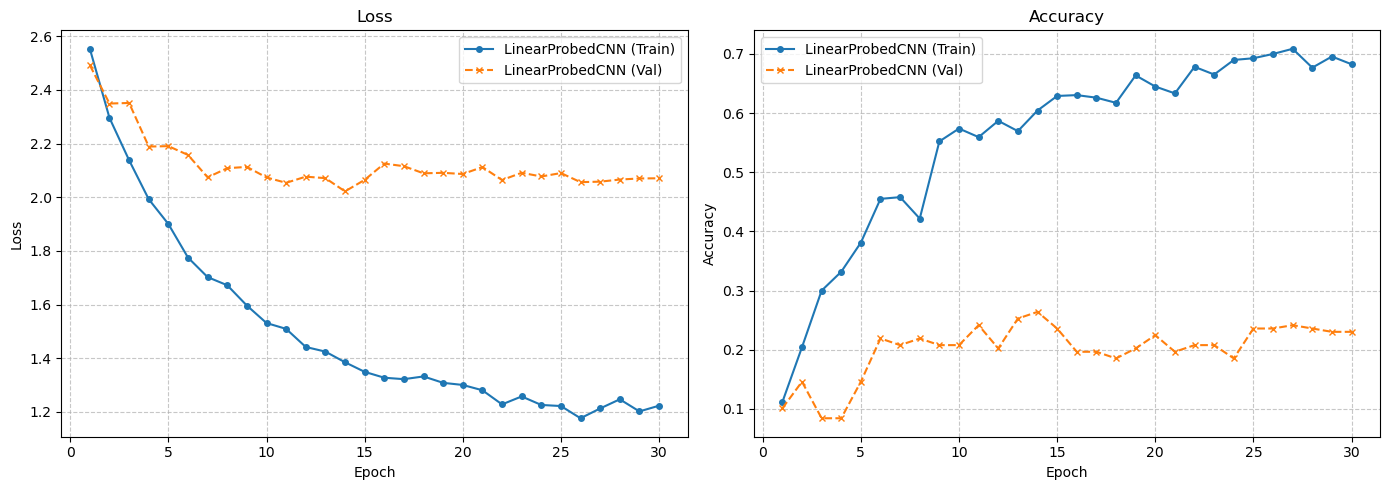

In [ ]:
import torch.optim as optim

torch.manual_seed(0)
model_tl = SequenceResNet(num_classes=13).to(device)
freeze_backbone(model_tl)
count_parameters(model_tl)

optimizer = optim.Adam(filter(lambda p: p.requires_grad, model_tl.parameters()), lr=1e-3)
criterion = nn.CrossEntropyLoss()
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30) # num_epochs

results = {}
results['LinearProbedCNN'] = run_experiment(model_tl, optimizer, criterion,
                                            train_loader, val_loader,
                                            epochs=30, name='LinearProbedCNN', scheduler=scheduler)

plot_experiments(results)

The model is heavily underfitting, can address this with a fine-tuned model later. However for now can work with the baseline to address the underfitting. The lowest loss of ~1.2 and lowest validation loss of ~2.05. To address this generalisation gap add a balanced weight decay of 1e-4 to not penalise the loss function too heavily and thereby inadvertently dropping performance.

  Trainable: 6,669 / 11,183,181 parameters (0.1%)
  [LinearProbedCNN] Epoch 1/30 — Train Loss: 2.5529, Train Acc: 0.1116 | Val Loss: 2.4917, Val Acc: 0.1011
  [LinearProbedCNN] Epoch 2/30 — Train Loss: 2.2954, Train Acc: 0.2043 | Val Loss: 2.3489, Val Acc: 0.1461
  [LinearProbedCNN] Epoch 3/30 — Train Loss: 2.1377, Train Acc: 0.3000 | Val Loss: 2.3510, Val Acc: 0.0843
  [LinearProbedCNN] Epoch 4/30 — Train Loss: 1.9924, Train Acc: 0.3319 | Val Loss: 2.1886, Val Acc: 0.0843
  [LinearProbedCNN] Epoch 5/30 — Train Loss: 1.9001, Train Acc: 0.3797 | Val Loss: 2.1902, Val Acc: 0.1461
  [LinearProbedCNN] Epoch 6/30 — Train Loss: 1.7750, Train Acc: 0.4551 | Val Loss: 2.1574, Val Acc: 0.2191
  [LinearProbedCNN] Epoch 7/30 — Train Loss: 1.7022, Train Acc: 0.4580 | Val Loss: 2.0739, Val Acc: 0.2079
  [LinearProbedCNN] Epoch 8/30 — Train Loss: 1.6719, Train Acc: 0.4217 | Val Loss: 2.1080, Val Acc: 0.2191
  [LinearProbedCNN] Epoch 9/30 — Train Loss: 1.5963, Train Acc: 0.5522 | Val Loss: 2.1128, Val

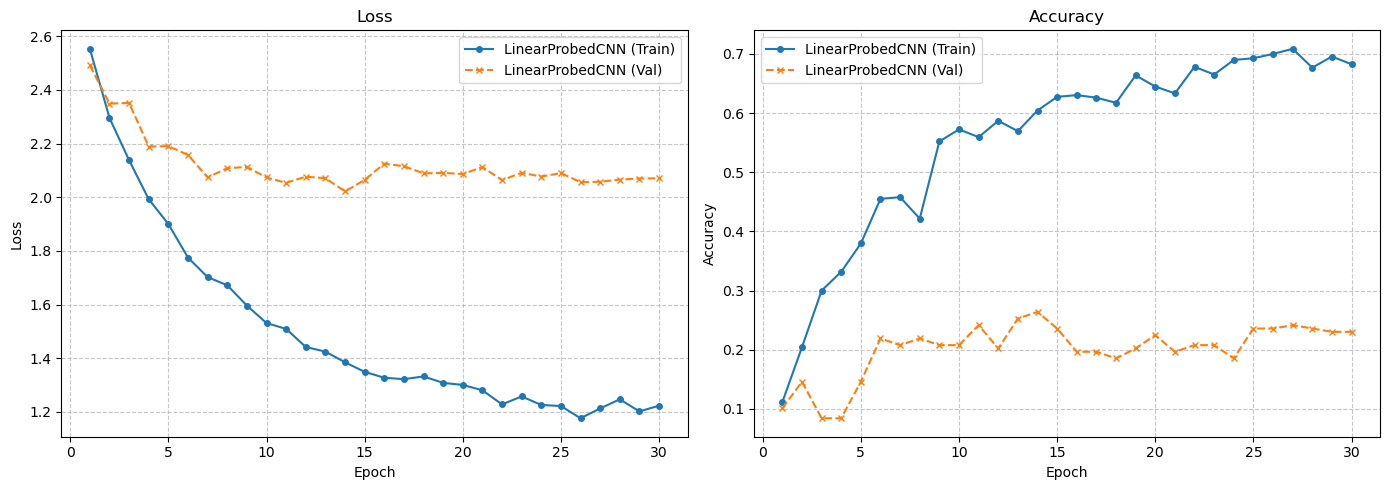

In [ ]:
import torch.optim as optim

torch.manual_seed(0)
model_tl = SequenceResNet(num_classes=13).to(device)
freeze_backbone(model_tl)
count_parameters(model_tl)

optimizer = optim.Adam(filter(lambda p: p.requires_grad, model_tl.parameters()), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30) # num_epochs

results = {}
results['LinearProbedCNN'] = run_experiment(model_tl, optimizer, criterion,
                                            train_loader, val_loader,
                                            epochs=30, name='LinearProbedCNN', scheduler=scheduler)

plot_experiments(results)

It seems the weight decay has not made a significant impact on the generalisation. This could mean the model may have irrelevant features rather than just large weights. However, more predominantly the model is underfitting and is too simple to capture the features in the images, meaning it has nothing regularise. The curves also suggest spiking, particularly the validation loss from epoch 14-16 the loss is going up. Try using a smaller learning rate such as 1e-4.

  Trainable: 6,669 / 11,183,181 parameters (0.1%)
  [LinearProbedCNN] Epoch 1/30 — Train Loss: 2.6392, Train Acc: 0.0899 | Val Loss: 2.7157, Val Acc: 0.0337
  [LinearProbedCNN] Epoch 2/30 — Train Loss: 2.5455, Train Acc: 0.1116 | Val Loss: 2.6184, Val Acc: 0.0618
  [LinearProbedCNN] Epoch 3/30 — Train Loss: 2.5329, Train Acc: 0.1188 | Val Loss: 2.5832, Val Acc: 0.0449
  [LinearProbedCNN] Epoch 4/30 — Train Loss: 2.4673, Train Acc: 0.1333 | Val Loss: 2.5977, Val Acc: 0.0449
  [LinearProbedCNN] Epoch 5/30 — Train Loss: 2.4484, Train Acc: 0.1435 | Val Loss: 2.5470, Val Acc: 0.0730
  [LinearProbedCNN] Epoch 6/30 — Train Loss: 2.4077, Train Acc: 0.1870 | Val Loss: 2.5549, Val Acc: 0.0674
  [LinearProbedCNN] Epoch 7/30 — Train Loss: 2.3881, Train Acc: 0.2058 | Val Loss: 2.5258, Val Acc: 0.0955
  [LinearProbedCNN] Epoch 8/30 — Train Loss: 2.3715, Train Acc: 0.2174 | Val Loss: 2.4962, Val Acc: 0.1011
  [LinearProbedCNN] Epoch 9/30 — Train Loss: 2.3491, Train Acc: 0.2087 | Val Loss: 2.4933, Val

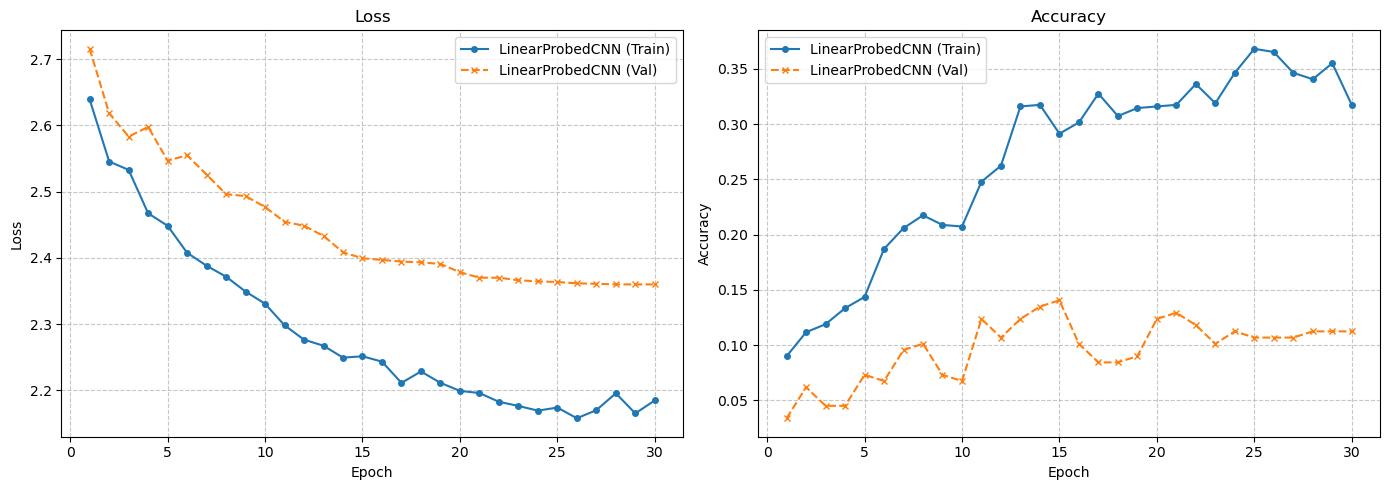

In [ ]:
import torch.optim as optim

torch.manual_seed(0)
model_tl = SequenceResNet(num_classes=13).to(device)
freeze_backbone(model_tl)
count_parameters(model_tl)

optimizer = optim.Adam(filter(lambda p: p.requires_grad, model_tl.parameters()), lr=1e-4)
criterion = nn.CrossEntropyLoss()
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30) # num_epochs

results = {}
results['LinearProbedCNN'] = run_experiment(model_tl, optimizer, criterion,
                                            train_loader, val_loader,
                                            epochs=30, name='LinearProbedCNN', scheduler=scheduler)

plot_experiments(results)

The loss curves are much smoother, however it is training way too slowly. Now try unfreezing the backbone for fine-tuning, of course with a smaller learning rate to not destroy the pre-trained features.

Fine-Tuning (continuing from linear probing)
  Trainable: 11,183,181 / 11,183,181 parameters (100.0%)
  [FineTunedCNN] Epoch 1/30 — Train Loss: 2.0423, Train Acc: 0.2609 | Val Loss: 3.0093, Val Acc: 0.1180
  [FineTunedCNN] Epoch 2/30 — Train Loss: 1.4759, Train Acc: 0.4522 | Val Loss: 3.1234, Val Acc: 0.0843
  [FineTunedCNN] Epoch 3/30 — Train Loss: 1.1954, Train Acc: 0.5754 | Val Loss: 3.0604, Val Acc: 0.0899
  [FineTunedCNN] Epoch 4/30 — Train Loss: 0.9347, Train Acc: 0.7449 | Val Loss: 2.5796, Val Acc: 0.2022
  [FineTunedCNN] Epoch 5/30 — Train Loss: 0.8666, Train Acc: 0.7739 | Val Loss: 2.5335, Val Acc: 0.1966
  [FineTunedCNN] Epoch 6/30 — Train Loss: 0.6723, Train Acc: 0.8797 | Val Loss: 2.3729, Val Acc: 0.2640
  [FineTunedCNN] Epoch 7/30 — Train Loss: 0.6110, Train Acc: 0.8768 | Val Loss: 2.3152, Val Acc: 0.2697
  [FineTunedCNN] Epoch 8/30 — Train Loss: 0.5900, Train Acc: 0.8870 | Val Loss: 2.2686, Val Acc: 0.2921
  [FineTunedCNN] Epoch 9/30 — Train Loss: 0.5443, Train Acc: 0.897

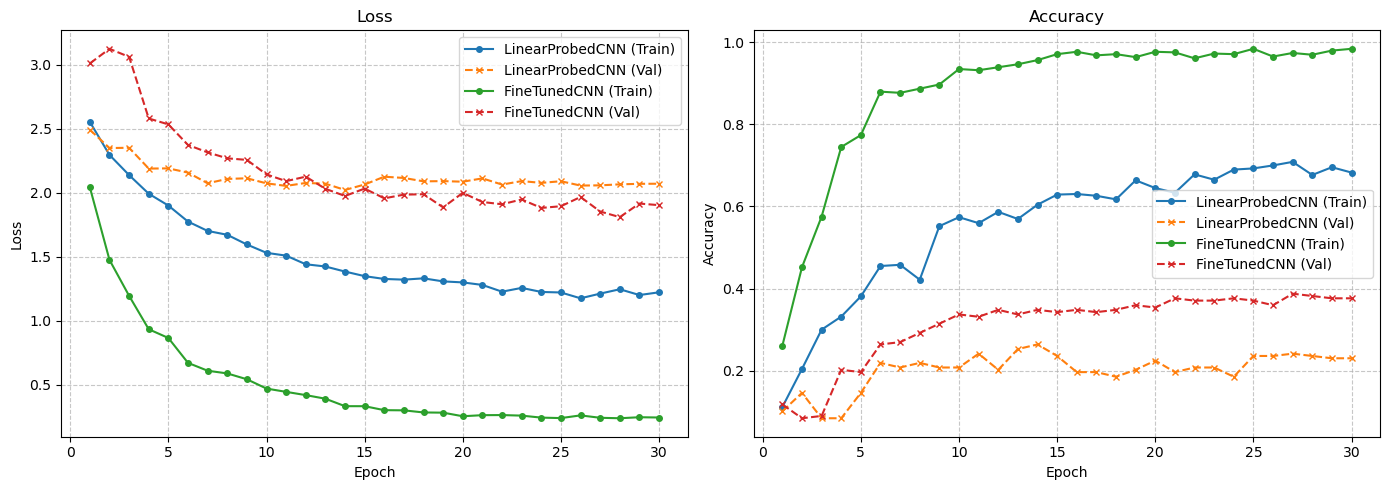

In [ ]:
# Unfreeze the backbone
unfreeze_backbone(model_tl)

print('Fine-Tuning (continuing from linear probing)')
count_parameters(model_tl)

# New optimiser with ALL parameters and a SMALLER learning rate
optimizer = optim.Adam(model_tl.parameters(), lr=1e-5)
criterion = nn.CrossEntropyLoss()
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30) # num_epochs

results['FineTunedCNN'] = run_experiment(
    model_tl, optimizer, criterion, train_loader, val_loader,
    epochs=30, name='FineTunedCNN', scheduler=scheduler
)

plot_experiments(results)

From the accuracy curves, the fine-tuned version is still not meeting our defined target. Could potentially increase the performance by training accross more epochs. However it is clear that this suboptimal approach of solving a sequential imaging classification task is a demonstration of the limitations of Convolutional Neural Networks (CNNs), particularly 2D CNNs (that processes images one at a time). A vision transfomer, or a Recurrent Neural Network is better suited for this task.

With only 690 training sequences, the baseline model struggles to capture spatial features from 15-channels. Because this is already a complex model, it can learn from more data if available.

## Misclassification Analysis

Val accuracy: 0.3764


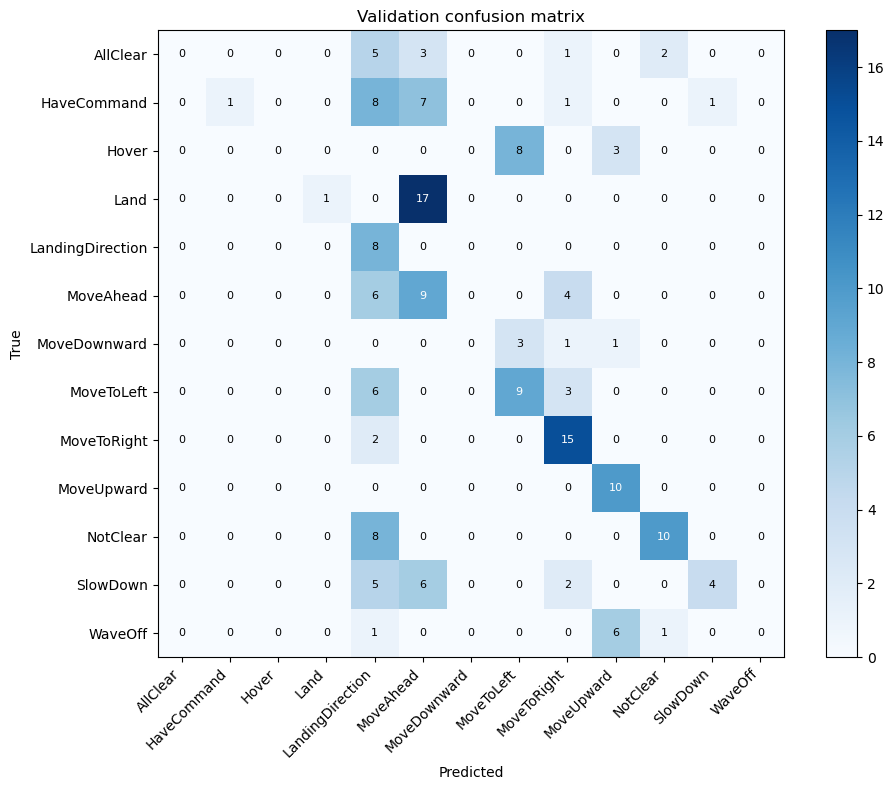

                  precision    recall  f1-score   support

        AllClear      0.000     0.000     0.000        11
     HaveCommand      1.000     0.056     0.105        18
           Hover      0.000     0.000     0.000        11
            Land      1.000     0.056     0.105        18
LandingDirection      0.163     1.000     0.281         8
       MoveAhead      0.214     0.474     0.295        19
    MoveDownward      0.000     0.000     0.000         5
      MoveToLeft      0.450     0.500     0.474        18
     MoveToRight      0.556     0.882     0.682        17
      MoveUpward      0.500     1.000     0.667        10
        NotClear      0.769     0.556     0.645        18
        SlowDown      0.800     0.235     0.364        17
         WaveOff      0.000     0.000     0.000         8

        accuracy                          0.376       178
       macro avg      0.419     0.366     0.278       178
    weighted avg      0.513     0.376     0.316       178

Most common

/home/ec2-user/anaconda3/envs/pytorch/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/ec2-user/anaconda3/envs/pytorch/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/ec2-user/anaconda3/envs/pytorch/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Predict on the validation set with the current (fine-tuned) model
model_tl.eval()
all_preds, all_labels = [], []
with torch.inference_mode():
    for x, y in val_loader:
        logits = model_tl(x.to(device))
        all_preds.append(logits.argmax(dim=1).cpu())
        all_labels.append(y)

y_true = torch.cat(all_labels).numpy()
y_pred = torch.cat(all_preds).numpy()
print(f'Val accuracy: {(y_true == y_pred).mean():.4f}')

# Confusion matrix (rows = true class, columns = predicted class)
cm = confusion_matrix(y_true, y_pred, labels=range(len(class_list)))

plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.title('Validation confusion matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(range(len(class_list)), class_list, rotation=45, ha='right')
plt.yticks(range(len(class_list)), class_list)
for i in range(len(class_list)):
    for j in range(len(class_list)):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()

print(classification_report(y_true, y_pred, target_names=class_list, digits=3))

# Rank the most common true -> predicted confusions
pairs = [(class_list[i], class_list[j], int(cm[i, j]))
         for i in range(len(class_list)) for j in range(len(class_list))
         if i != j and cm[i, j] > 0]
pairs.sort(key=lambda p: p[2], reverse=True)
print('Most common confusions (true -> predicted):')
for t, p, c in pairs[:8]:
    print(f'  {t:<18} -> {p:<18} {c}')

Final validation accuracy: ~37.6%. Macro-averaged F1: ~27.8%. Macro F1 score is even lower than accuracy even though the imabalance in dataset. - The model is severly underfitting and failing to learn meaningful distinct features.

The weighted F1 average is ~31.6% which is higher than the macro F1, confirming that the model performs better on classes with more samples such as MoveToRight and NotClear, while failing on rarer classes.

Four classes have 0 F1-score: AllClear, Hover, MoveDownward and WaveOff are never correctly predicted (0 precision and recall as well). The model seems to completely ignore these classes.

The model collapses toward LandingDirection, defaulting to predicting LandingDirection for most inputs (perfect recall 1, but low precision 0.163), meaning most of its LandingDirection predictions are actually wrong.

Most common confusions include True class: Land, Predicted class: MoveAhead with 17. Also from data exploration, Hover and MoveToLeft were to observed to have similar frames, which seems to correlate with this confusion matrix. The true class being Hover, and the predicted class being MoveToLeft with 8.

Better classes include MoveToRight (F1=68.2%) and MoveUpward (F1=66.7%) perform best. This suggests the model can partially distinguish directional gestures.

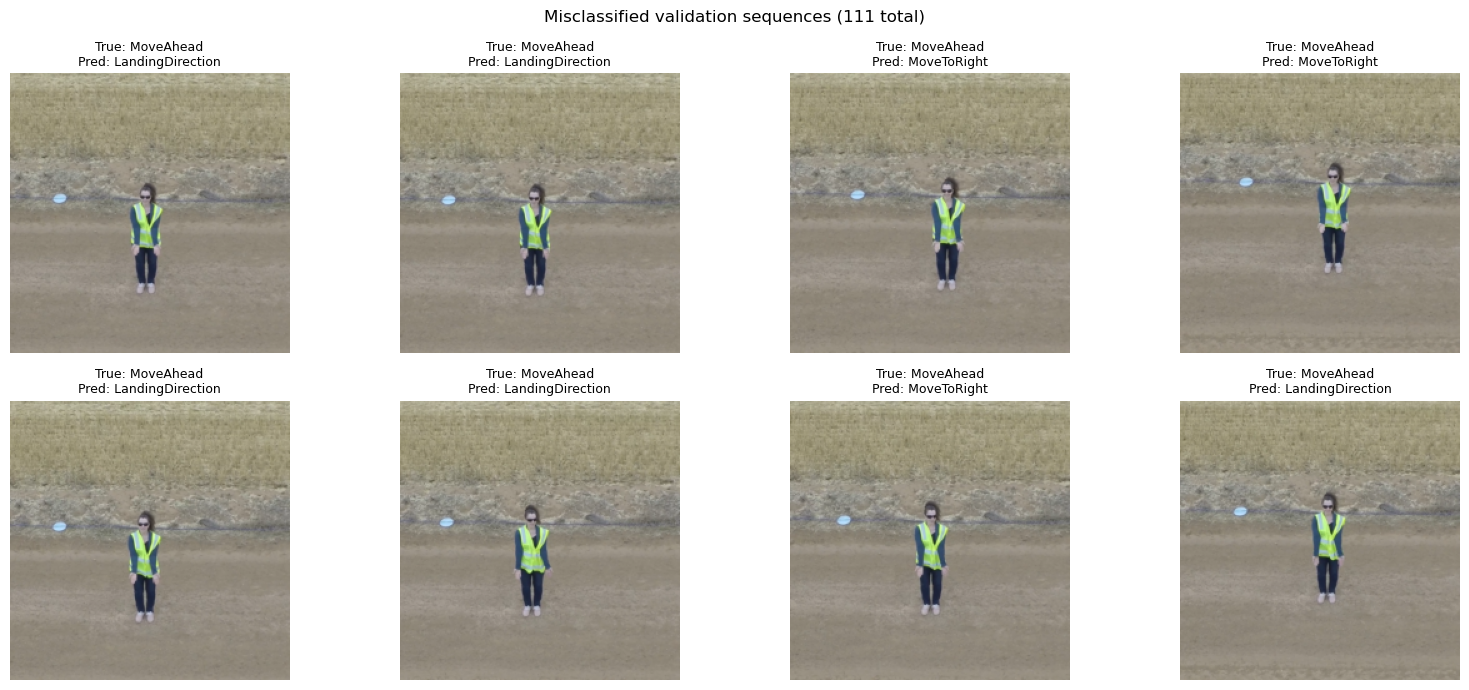

In [ ]:
# Collect and visualise misclassified validation sequences (first frame shown)
misclassified = []
model_tl.eval()
with torch.inference_mode():
    for x, y in val_loader:
        preds = model_tl(x.to(device)).argmax(dim=1).cpu()
        mask = preds != y
        if mask.any():
            misclassified.append((x[mask], y[mask], preds[mask]))

if misclassified:
    xs = torch.cat([m[0] for m in misclassified])
    ys = torch.cat([m[1] for m in misclassified])
    ps = torch.cat([m[2] for m in misclassified])

    # Undo ImageNet normalisation for display
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

    n = min(8, len(xs))
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for k in range(n):
        ax = axes[k // 4][k % 4]
        img = xs[k, 0] * std + mean  # first frame of the sequence
        ax.imshow(img.clamp(0, 1).permute(1, 2, 0))
        ax.set_title(f'True: {class_list[ys[k]]}\nPred: {class_list[ps[k]]}', fontsize=9)
        ax.axis('off')
    for ax in axes.flat[n:]:
        ax.axis('off')
    plt.suptitle(f'Misclassified validation sequences ({len(xs)} total)')
    plt.tight_layout()
    plt.show()
else:
    print('No misclassified sequences!')

Visually similar gesture pairs are confused. For this example, comparing MoveAhead the true class, with other predicted classes. As noted before, the signal-to-noise ratio is poor, where the subject is small relative to the background.

In [ ]:
model_tl.eval()
test_loss, test_acc = evaluate(model_tl, test_loader, criterion)
print(f'Final Test Accuracy: {test_acc:.4f}')

Final Test Accuracy: 0.3613


These are sequential gestures (5 frames showing motion). Stacking frames into 15 channels just to fit a 2D CNN discards temporal ordering when static frames look similar.

Target quota of 80% accuracy not met. This is not deployment ready. A more complex model is required to reach the ~99% accuracy for an emergency field.

## Save the Model

In [ ]:
import os

# Create a directory for saving models
MODEL_PATH = "models"
os.makedirs(MODEL_PATH, exist_ok=True)

# Save the model's learned parameters (state_dict)
MODEL_NAME = "linear_regression_model.pth"
MODEL_SAVE_PATH = os.path.join(MODEL_PATH, MODEL_NAME)

torch.save(model.state_dict(), MODEL_SAVE_PATH)
print(f"Model saved to: {MODEL_SAVE_PATH}")

Model saved to: Model saved to: models/linear_regression_model.pth


# Part B – Recommendation System

- Even though the demo succeeded, from the testing score, the gesture-recognition model predicted ~36% correct gestures out of the total predictions. This did not meet the target of 80% correct predictions. Keeping the gesture-recognition model as-is is not my recommendation.
- Despite the bare-metal required to execute this simpler model (see Baseline CNN) is far less constrained than with more complex models, the fact that the client does not require further model testing is a red flag. A key challenge includes fitting the model in a drone, rather than a typical computer, because of differing bare-metal.
- I would vigorously test the model before shipping it, to check for errors and address any failures as best I can (see Misclassification Analysis).
- Risks for shipping the model as-is include incorrectly matching a gesture, for example the model consistently matches the MoveAhead gesture with an incorrect actual gesture (see Misclassifed Images). - Which could be consequential in the emergency medical context. Does the drone abort or continue? What happens when the drone delivers to a wrong location?
- Physically testing the model before shipping itself is a difficult problem, because a controlled environment would be needed to simulate the real-world medical context to deliver the supplies.
- Also, shipping this model as is on the limited data images (see Data Splitting); is not enough gesture instances. Compare this to other shipped models on ~1.3 million images (see Transfer Learning ResNet18).
- Because a regional emergency-services provider wants a drone capable of delivering time-critical medical supplies, RedKite Aerospace Australia would need the model on more data, ideally in more medical contexts. Such as images used to train a model in this paper: https://www.sciencedirect.com/science/article/pii/S1568494625015352. The sample images that can be found in the full PDF report. The team focused on gesture recognition in drone control on multi-distance, which can help when delivering medical supplies when the gesture is perfomed long-distance.
- Also, the drone might need to be able to see the subjects performing the gestures in the dark, again pointing to the model's weakness of limited data which only showed subjects performing the gestures in the daytime (see Data Exploration images).
- I would also implement a human-in-the-loop system for this model, watching the drone's actions, especially for high-risk deliveries.
- Questions surround how is the model going to be maintained when its in operation in the drone. Does the bare-metal need changing after a model change? Can the upgrades be performed automatically? The system as a whole needs to be tested including the drone's capability to correctly read the gestures while simultaneously moving around and delivering the supplies without hitting any obstacles or people. Or causing any harm to the emergency crew or patients involved. It is unclear who would be accountable for such incidences, so I would try my best to mitigate these possibilities before shipping the model.